# Geographic Data Understanding

## 1. Introduction and Objectives

This notebook explores the geographic characteristics of Airbnb listings in Milan and investigates how location relates to nightly prices.

It extends the exploratory analysis conducted for Model 1, which focused on structural property features. The objective is to identify potentially useful geographic predictors for Model 2, while preserving the same listing selection criteria.

The analysis focuses on geographic data quality, spatial distribution, neighbourhood-level price differences, and distance from Milan's city centre.

Findings are descriptive and will guide subsequent data preparation and modelling decision

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

cwd = Path.cwd().resolve()
if (cwd / "data" / "raw" / "listings.csv.gz").exists():
    project_root = cwd
elif (cwd.parent / "data" / "raw" / "listings.csv.gz").exists():
    project_root = cwd.parent
else:
    raise FileNotFoundError("Expected data/raw/listings.csv.gz in the project root.")

data_path = project_root / "data" / "raw" / "listings.csv.gz"
df = pd.read_csv(data_path, low_memory=False)
print("Dataset shape:", df.shape)

Dataset shape: (25338, 90)


## 2. Dataset Overview and Geographic Variables

To ensure comparability with Model 1, the analysis focuses on listings with a positive nightly price of up to €1,000 and includes only Entire home/apt and Private room listings.

The geographic variables examined are latitude, longitude, and neighbourhood_cleansed.

This section describes the selected sample and assesses the availability and basic characteristics of the geographic information.

In [2]:
# Convert nightly prices to numeric values
df["price_numeric"] = pd.to_numeric(
    df["price"].astype("string").str.replace(
        r"[$,]", "", regex=True
    ),
    errors="coerce"
)

# Apply the same listing selection criteria as Model 1
df_geo = df.loc[
    (df["price_numeric"] > 0)
    & (df["price_numeric"] <= 1000)
    & (df["room_type"].isin(["Entire home/apt", "Private room"]))
].copy()

print("Selected listings:", len(df_geo))
print("\nGeographic variables:")
df_geo[["latitude", "longitude", "neighbourhood_cleansed"]].info()


Selected listings: 21314

Geographic variables:
<class 'pandas.core.frame.DataFrame'>
Index: 21314 entries, 0 to 25337
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   latitude                21314 non-null  float64
 1   longitude               21314 non-null  float64
 2   neighbourhood_cleansed  21314 non-null  object 
dtypes: float64(2), object(1)
memory usage: 666.1+ KB


## 3. Geographic Data Quality

Before exploring spatial patterns, the quality of geographic information is assessed.

The analysis examines missing values, coordinate ranges, duplicated coordinate pairs, and neighbourhood coverage.

The objective is to identify potential data quality issues without prematurely removing or modifying observations.

In [3]:
# We consider latitude, longitude and quartiere
geo_cols = ['latitude',"longitude","neighbourhood_cleansed"]

#Missing values
missing_values = df_geo[geo_cols].isna().sum()

#Neighbourhood coverage
n_neighbourhood = df_geo["neighbourhood_cleansed"].nunique()

# Coordinate ranges
coordinate_summary = df_geo[
    ["latitude", "longitude"]
].describe()

# Duplicate coordinate pairs
duplicate_coordinates = df_geo.duplicated(
    subset=["latitude", "longitude"],
    keep=False
).sum()


print("Missing values:")
print(missing_values)

print("\nNumber of distinct neighbourhood:", n_neighbourhood)

print("\nCoordinate summary:")
display(coordinate_summary)

print(
    "\nListings sharing coordinates with at least "
    "one other listing:",
    duplicate_coordinates
)

duplicate_percentage = (
    duplicate_coordinates / len(df_geo) * 100
)

print(
    f"Listings sharing coordinates: "
    f"{duplicate_percentage:.2f}%"
)

Missing values:
latitude                  0
longitude                 0
neighbourhood_cleansed    0
dtype: int64

Number of distinct neighbourhood: 87

Coordinate summary:


,latitude,longitude
count,21314.000000,21314.000000
mean,45.471540,9.187621
std,0.020410,0.029078
min,45.397080,9.066860
25%,45.455357,9.170732
50%,45.471431,9.187973
75%,45.486445,9.208890
max,45.533340,9.265690



Listings sharing coordinates with at least one other listing: 3777
Listings sharing coordinates: 17.72%


In [4]:
coordinate_counts = (
    df_geo
    .groupby(["latitude", "longitude"])
    .size()
    .sort_values(ascending=False)
)

shared_locations = coordinate_counts[coordinate_counts > 1]

print("Unique coordinate pairs:", len(coordinate_counts))
print("Coordinate pairs shared by multiple listings:", len(shared_locations))
print("Listings at shared coordinates:", shared_locations.sum())
print("Maximum listings at one coordinate pair:", coordinate_counts.max())

display(coordinate_counts.head(10))

Unique coordinate pairs: 18919
Coordinate pairs shared by multiple listings: 1382
Listings at shared coordinates: 3777
Maximum listings at one coordinate pair: 52


latitude   longitude
45.450294  9.200944     52
45.468292  9.173558     51
45.465863  9.177458     43
45.458480  9.210740     22
45.464601  9.182199     12
45.486087  9.197738     11
45.447840  9.163119     11
45.507632  9.102425     10
45.504411  9.127270     10
45.463402  9.187450     10
dtype: int64

### Geographic Data Quality: Key Findings

The geographic variables show good overall completeness:

- No missing values were found in latitude, longitude, or neighbourhood_cleansed.
- The selected sample covers 87 distinct neighbourhoods.
- Latitude ranges from approximately 45.397 to 45.533, while longitude ranges from 9.067 to 9.266. These ranges appear geographically plausible for Milan.
- A total of 3,777 listings (17.7%) share their exact coordinate pair with at least one other listing.

Shared coordinates do not necessarily indicate data quality problems. They may reflect multiple listings within the same building or approximate location information.

At this stage, no observations are removed based on geographic information. Further spatial visualisation will help identify potential geographic anomalies.

### Shared Coordinates: Additional Findings

The dataset contains 18,919 unique coordinate pairs. Among these, 1,382 pairs are shared by multiple listings, accounting for 3,777 listings (17.7% of the selected sample).

The most frequently shared coordinate pair is associated with 52 listings, followed by locations with 51 and 43 listings.

These findings indicate that exact coordinate duplication occurs across many locations rather than being limited to a single cluster. Possible explanations include multiple listings within the same building and approximate geographic coordinates.

Shared coordinates alone do not provide sufficient evidence of data errors. Therefore, all listings are retained for subsequent analysis.

## 4. Spatial Distribution of Listings

This section explores the spatial distribution of Airbnb listings across Milan.

A scatter plot of longitude and latitude is used to identify geographic concentrations, less represented areas, and potential spatial anomalies.

The analysis is descriptive and does not yet consider differences in nightly prices.

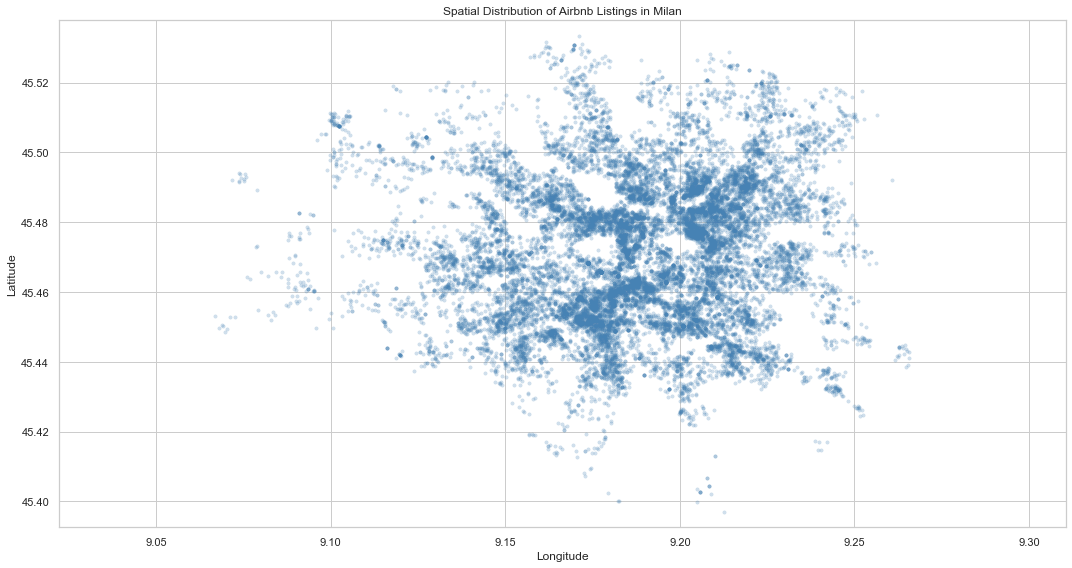

In [5]:
plt.figure(figsize=(15,8))

sns.scatterplot(data=df_geo,
               x="longitude",
               y="latitude",
               s=12,
               alpha=0.25,
               color="steelblue",
               edgecolor=None)

plt.title("Spatial Distribution of Airbnb Listings in Milan")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.axis("equal")
plt.tight_layout()
plt.show()

### Spatial Distribution: Key Findings

The scatter plot reveals a non-uniform spatial distribution of Airbnb listings across Milan.

- Listings are strongly concentrated in the central part of the observed geographic area.
- Several high-density clusters are visible, suggesting that accommodation supply varies considerably across the city.
- Listings become generally more dispersed towards the outer areas.
- A limited number of listings appear relatively isolated from the main concentrations.

These observations suggest that geographic location may contain useful information for predicting nightly prices.

However, the scatter plot only describes listing locations. It does not establish a relationship between geographic position and price.

Further analysis will investigate spatial price differences and the potential contribution of geographic features to Model 2.

### 4.1 Interactive Map of Airbnb Listings

An interactive map is created using Folium to explore the geographic distribution of listings across Milan.

Marker clustering is used to improve readability when multiple listings are located close to one another.

The map is intended for exploratory purposes and does not represent listing prices.

In [6]:
import folium
from folium.plugins import FastMarkerCluster

# Centre the map on the approximate centre of the listings
map_center = [
    df_geo["latitude"].median(),
    df_geo["longitude"].median()
]

milan_map = folium.Map(
    location=map_center,
    zoom_start=12,
    tiles="OpenStreetMap"
)

# Prepare coordinates
locations = df_geo[
    ["latitude", "longitude"]
].dropna().values.tolist()

# Add clustered markers
FastMarkerCluster(locations).add_to(milan_map)

# Display interactive map
milan_map

### Interactive Map: Observations

The interactive map provides a more detailed view of the spatial distribution of Airbnb listings across Milan.

Marker clustering improves the visualisation of densely populated areas and allows users to explore listing locations at different zoom levels.

Together with the static scatter plot, the map highlights the uneven geographic distribution of listings and helps distinguish dense clusters from more isolated locations.

However, marker clusters represent geographic proximity rather than exact coordinate duplication. The map does not establish whether location influences nightly prices.

The next section investigates geographic differences in listing prices.

## 5. Geographic Distribution of Prices

This section investigates how nightly prices vary across Milan's neighbourhoods.

The analysis focuses on median prices and listing counts to identify geographic differences while accounting for the unequal representation of neighbourhoods.

Median prices are preferred over mean prices because they are less sensitive to unusually expensive listings.

The results are descriptive and do not establish a causal relationship between location and price.

In [7]:
# Summarise nightly prices by neighbourhood
neighbourhood_prices = (
    df_geo
    .groupby("neighbourhood_cleansed")
    .agg(
        listing_count=("price_numeric", "size"),
        median_price=("price_numeric", "median"),
        mean_price=("price_numeric", "mean")
    )
    .sort_values("listing_count", ascending=False)
)

print("Number of neighbourhoods:", len(neighbourhood_prices))

display(neighbourhood_prices.head(15))

Number of neighbourhoods: 87


,listing_count,median_price,mean_price
neighbourhood_cleansed,,,
BUENOS AIRES - VENEZIA,1730,180.0,205.985844
DUOMO,1568,293.25,330.985517
CENTRALE,1035,175.5,200.588464
SARPI,950,166.55,189.788611
BRERA,935,247.0,284.949369
NAVIGLI,830,166.415,186.157904
TICINESE,792,170.0,191.148977
LORETO,769,134.0,150.464811
ISOLA,697,157.5,175.862224


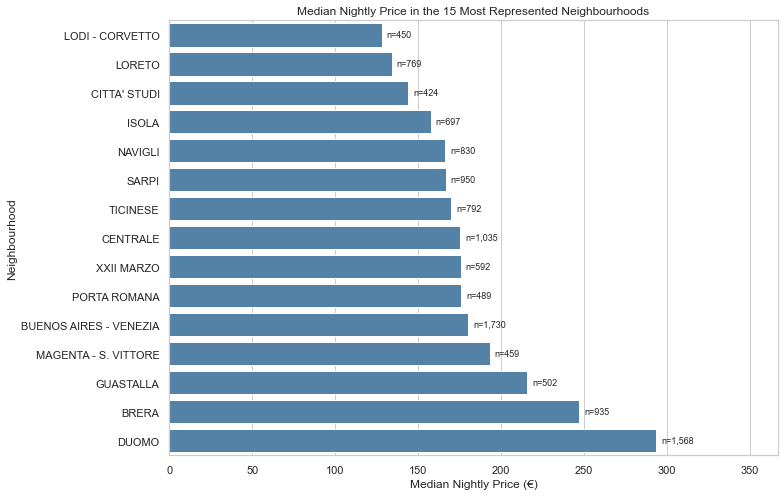

In [8]:
top_neighbourhoods = (
    neighbourhood_prices
    .head(15)
    .sort_values("median_price", ascending=True)
)

fig, ax = plt.subplots(figsize=(11, 7))

sns.barplot(
    data=top_neighbourhoods,
    x="median_price",
    y=top_neighbourhoods.index,
    color="steelblue",
    ax=ax
)

# Add listing counts next to each bar
for i, (_, row) in enumerate(top_neighbourhoods.iterrows()):
    ax.text(
        row["median_price"] + 3,
        i,
        f'n={int(row["listing_count"]):,}',
        va="center",
        fontsize=9
    )

ax.set_xlim(0, top_neighbourhoods["median_price"].max() * 1.25)

ax.set_title("Median Nightly Price in the 15 Most Represented Neighbourhoods")
ax.set_xlabel("Median Nightly Price (€)")
ax.set_ylabel("Neighbourhood")

plt.tight_layout()
plt.show()

### Neighbourhood-Level Price Differences: Key Findings

Nightly prices vary considerably across the 15 most represented neighbourhoods in Milan.

- DUOMO has the highest median nightly price (€293.25), followed by BRERA (€247.00).
- LODI - CORVETTO (€128.07) and LORETO (€134.00) show the lowest median prices among the selected neighbourhoods.
- Several neighbourhoods have median prices between approximately €150 and €200.
- These differences are observed across neighbourhoods with substantial listing counts, making the descriptive comparisons more informative.
- Mean prices exceed median prices in all 15 neighbourhoods, suggesting positively skewed price distributions.

These findings indicate a clear association between neighbourhood and nightly price.

However, neighbourhood-level price differences may also reflect variations in property characteristics, accommodation capacity, and room type.

Therefore, the observed differences cannot be attributed exclusively to geographic location.

The results support investigating neighbourhood information as a potential predictor in Model 2.

### 5.1 Neighbourhood Prices by Room Type

Neighbourhood-level price differences may partly reflect variations in the composition of accommodation types.

To investigate this possibility, median nightly prices are compared separately for Entire home/apt and Private room listings.

The analysis focuses on the 15 most represented neighbourhoods, maintaining consistency with the previous comparison.

This remains a descriptive analysis and does not control for other structural property characteristics.

In [9]:
# Select the 15 most represented neighbourhoods
top_15_names = neighbourhood_prices.head(15).index

# Calculate median prices and listing counts by room type
room_type_prices = (
    df_geo[
        df_geo["neighbourhood_cleansed"].isin(top_15_names)
    ]
    .groupby(["neighbourhood_cleansed", "room_type"])
    .agg(
        listing_count=("price_numeric", "size"),
        median_price=("price_numeric", "median")
    )
    .reset_index()
)

# Display median prices by room type
median_by_room_type = room_type_prices.pivot(
    index="neighbourhood_cleansed",
    columns="room_type",
    values="median_price"
)

display(median_by_room_type.round(2))

room_type,Entire home/apt,Private room
neighbourhood_cleansed,,
BRERA,250.0,161.0
BUENOS AIRES - VENEZIA,184.07,140.35
CENTRALE,180.0,143.85
CITTA' STUDI,149.27,88.84
DUOMO,294.35,284.18
GUASTALLA,220.93,172.0
ISOLA,163.75,101.0
LODI - CORVETTO,133.15,78.72
LORETO,137.56,82.5


In [10]:
# Listing counts by neighbourhood and room type
counts_by_room_type = room_type_prices.pivot(
    index="neighbourhood_cleansed",
    columns="room_type",
    values="listing_count"
)

display(counts_by_room_type)

room_type,Entire home/apt,Private room
neighbourhood_cleansed,,
BRERA,883,52
BUENOS AIRES - VENEZIA,1536,194
CENTRALE,851,184
CITTA' STUDI,383,41
DUOMO,1464,104
GUASTALLA,453,49
ISOLA,626,71
LODI - CORVETTO,370,80
LORETO,674,95


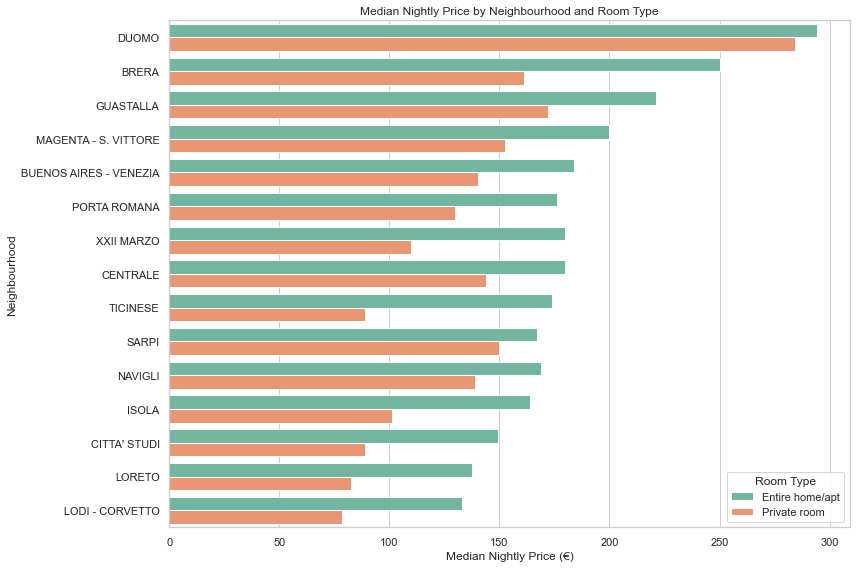

In [11]:
# Order neighbourhoods by overall median nightly price
neighbourhood_order = (
    neighbourhood_prices
    .head(15)
    .sort_values("median_price", ascending=False)
    .index
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=room_type_prices,
    x="median_price",
    y="neighbourhood_cleansed",
    hue="room_type",
    order=neighbourhood_order,
    palette="Set2"
)

plt.title("Median Nightly Price by Neighbourhood and Room Type")
plt.xlabel("Median Nightly Price (€)")
plt.ylabel("Neighbourhood")
plt.legend(title="Room Type")

plt.tight_layout()
plt.show()

### 5.2 Private Room to Entire Home Price Ratio

To further investigate differences between accommodation types, the ratio between the median nightly price of private rooms and entire homes is calculated for each neighbourhood.

This analysis examines whether the relative price of private rooms is approximately stable across neighbourhoods or varies substantially by location.

In [12]:
# Calculate the ratio of median prices by room type
price_ratio = median_by_room_type.copy()

price_ratio["private_to_entire_ratio"] = (
    price_ratio["Private room"] /
    price_ratio["Entire home/apt"]
)

# Add listing counts for both room types
price_ratio["entire_count"] = counts_by_room_type["Entire home/apt"]
price_ratio["private_count"] = counts_by_room_type["Private room"]

# Sort neighbourhoods by price ratio
price_ratio = price_ratio.sort_values(
    "private_to_entire_ratio",
    ascending=False
)

display(price_ratio.round(3))

room_type,Entire home/apt,Private room,private_to_entire_ratio,entire_count,private_count
neighbourhood_cleansed,,,,,
DUOMO,294.35,284.18,0.965,1464,104
SARPI,167.0,150.0,0.898,861,89
NAVIGLI,168.75,139.0,0.824,766,64
CENTRALE,180.0,143.85,0.799,851,184
GUASTALLA,220.93,172.0,0.779,453,49
MAGENTA - S. VITTORE,200.0,152.52,0.763,423,36
BUENOS AIRES - VENEZIA,184.07,140.35,0.762,1536,194
PORTA ROMANA,176.0,129.665,0.737,463,26
BRERA,250.0,161.0,0.644,883,52


Pearson correlation: -0.103


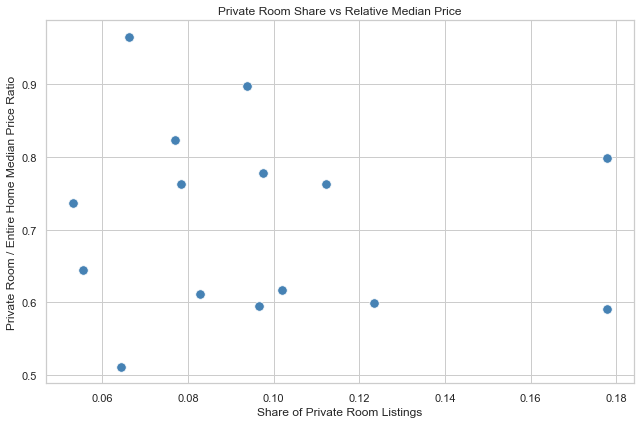

In [13]:
# Calculate the share of private rooms in each neighbourhood
price_ratio["private_room_share"] = (
    price_ratio["private_count"] /
    (
        price_ratio["private_count"]
        + price_ratio["entire_count"]
    )
)

# Examine the association between private room share
# and the relative median price of private rooms
correlation = price_ratio[
    ["private_room_share", "private_to_entire_ratio"]
].corr().iloc[0, 1]

print(f"Pearson correlation: {correlation:.3f}")

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=price_ratio,
    x="private_room_share",
    y="private_to_entire_ratio",
    s=90,
    color="steelblue"
)

plt.title("Private Room Share vs Relative Median Price")
plt.xlabel("Share of Private Room Listings")
plt.ylabel("Private Room / Entire Home Median Price Ratio")

plt.tight_layout()
plt.show()

### Private Room Price Ratios: Key Findings

The ratio between private room and entire home median nightly prices varies considerably across the 15 most represented neighbourhoods, ranging from approximately 0.51 to 0.97.

DUOMO shows the highest ratio (0.965), followed by SARPI (0.898) and NAVIGLI (0.824).

To investigate whether relative prices are associated with the local composition of listings, the share of private rooms was compared with the median price ratio.

The Pearson correlation coefficient is -0.103, indicating a very weak linear association across the 15 neighbourhoods.

Therefore, the analysis does not provide clear evidence that neighbourhoods with fewer private room listings have systematically higher relative private room prices.

Differences in sample sizes may affect the stability of neighbourhood-level median estimates. However, the observed variation may also reflect differences in property characteristics, listing composition, and local market conditions.

Further investigation would be required to distinguish these explanations.

Overall, the results suggest that the relationship between geographic location, accommodation type, and nightly price is not uniform across Milan.

## 6. Distance from Milan City Centre

This section investigates the relationship between nightly prices and geographic distance from Milan's city centre.

Milan Cathedral (Duomo di Milano) is used as a reference point because of its central location and relevance to the city's urban geography.

The Haversine formula is used to calculate the approximate great-circle distance between each listing and the Duomo, expressed in kilometres.

These distances represent geographic proximity rather than actual walking, driving, or public transport distances.

The objective is to explore whether nightly prices tend to vary with distance from the city centre.

In [14]:
# Approximate coordinates of Milan Cathedral
duomo_lat = 45.4642
duomo_lon = 9.1916

# Earth's mean radius in kilometres
earth_radius = 6371.0

# Convert geographic coordinates to radians
lat1 = np.radians(df_geo["latitude"])
lon1 = np.radians(df_geo["longitude"])

lat2 = np.radians(duomo_lat)
lon2 = np.radians(duomo_lon)

# Calculate Haversine distance
delta_lat = lat1 - lat2
delta_lon = lon1 - lon2

a = (
    np.sin(delta_lat / 2) ** 2
    + np.cos(lat1)
    * np.cos(lat2)
    * np.sin(delta_lon / 2) ** 2
)

c = 2 * np.arctan2(
    np.sqrt(a),
    np.sqrt(1 - a)
)

df_geo["distance_duomo_km"] = earth_radius * c

# Summarise calculated distances
display(df_geo["distance_duomo_km"].describe().round(2))

count    21314.00
mean         2.94
std          1.56
min          0.03
25%          1.80
50%          2.76
75%          3.78
max          9.84
Name: distance_duomo_km, dtype: float64

In [15]:
# Euclidean distance approximation (km)
delta_lat_km = (
    df_geo["latitude"] - duomo_lat
) * 111.195

delta_lon_km = (
    df_geo["longitude"] - duomo_lon
) * 111.195 * np.cos(np.radians(duomo_lat))

df_geo["distance_euclidean_km"] = np.sqrt(
    delta_lat_km**2 + delta_lon_km**2
)

# Compare Euclidean and Haversine distances
display(
    df_geo[
        ["distance_duomo_km", "distance_euclidean_km"]
    ].describe().round(4)
)

,distance_duomo_km,distance_euclidean_km
count,21314.0000,21314.0000
mean,2.9385,2.9385
std,1.5556,1.5557
min,0.0344,0.0344
25%,1.8046,1.8047
50%,2.7630,2.7630
75%,3.7834,3.7833
max,9.8445,9.8467


### 6.1 Distance from the Duomo and Nightly Prices

Both Haversine and locally approximated Euclidean distances were calculated. Their descriptive statistics are nearly identical, indicating that the choice of distance metric has a negligible practical impact within the geographic extent of this dataset.

Haversine distance is used for the following exploratory analysis.

To investigate the relationship between distance and nightly price, listings are grouped into one-kilometre distance intervals. Median nightly prices and listing counts are calculated for each interval.

This approach helps identify potential non-linear patterns while reducing the influence of individual high-priced listings.

In [16]:
# Create 1-km distance intervals
df_geo["distance_band"] = pd.cut(
    df_geo["distance_duomo_km"],
    bins=np.arange(0, 12, 1),
    right=False
)

# Summarise prices by distance interval
distance_prices = (
    df_geo
    .groupby("distance_band", observed=True)
    .agg(
        listing_count=("price_numeric", "size"),
        median_price=("price_numeric", "median"),
        mean_price=("price_numeric", "mean")
    )
)

display(distance_prices.round(2))

,listing_count,median_price,mean_price
distance_band,,,
"[0, 1)",1744,297.0,333.85
"[1, 2)",4828,193.0,225.04
"[2, 3)",5545,166.0,190.86
"[3, 4)",4661,143.0,163.18
"[4, 5)",2405,130.75,145.66
"[5, 6)",1118,129.0,149.24
"[6, 7)",671,123.0,139.61
"[7, 8)",211,115.0,137.91
"[8, 9)",111,142.8,164.93


In [17]:
# Create 0.5-km distance intervals
df_geo["distance_band_05"] = pd.cut(
    df_geo["distance_duomo_km"],
    bins=np.arange(0, 10.5, 0.5),
    right=False
)

# Summarise prices by 0.5-km interval
distance_prices_05 = (
    df_geo
    .groupby("distance_band_05", observed=True)
    .agg(
        listing_count=("price_numeric", "size"),
        median_price=("price_numeric", "median"),
        mean_price=("price_numeric", "mean")
    )
)

display(distance_prices_05.round(2))

,listing_count,median_price,mean_price
distance_band_05,,,
"[0.0, 0.5)",574,332.23,372.89
"[0.5, 1.0)",1170,277.32,314.7
"[1.0, 1.5)",1756,205.62,238.92
"[1.5, 2.0)",3072,187.0,217.11
"[2.0, 2.5)",2789,171.0,197.29
"[2.5, 3.0)",2756,159.44,184.34
"[3.0, 3.5)",2500,147.32,168.67
"[3.5, 4.0)",2161,137.0,156.83
"[4.0, 4.5)",1389,131.0,145.89


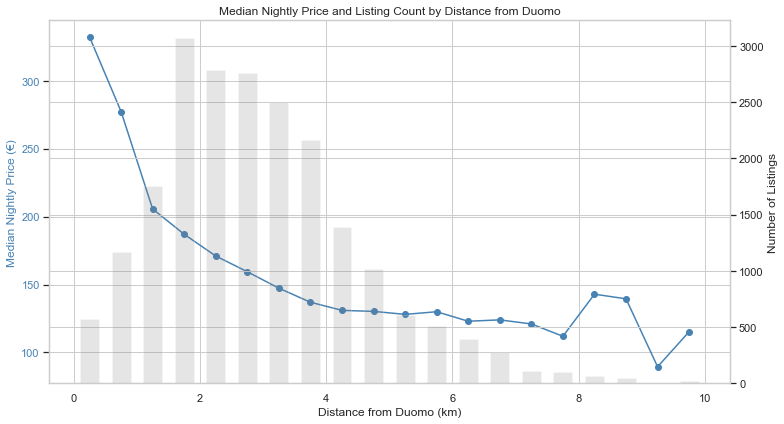

In [18]:
# Midpoint of each 0.5-km distance interval
distance_plot = distance_prices_05.copy()

distance_plot["distance_km"] = [
    interval.mid
    for interval in distance_plot.index
]

fig, ax1 = plt.subplots(figsize=(11, 6))

# Median nightly price
ax1.plot(
    distance_plot["distance_km"],
    distance_plot["median_price"],
    marker="o",
    color="steelblue",
    label="Median nightly price"
)

ax1.set_xlabel("Distance from Duomo (km)")
ax1.set_ylabel("Median Nightly Price (€)", color="steelblue")
ax1.tick_params(axis="y", labelcolor="steelblue")

# Listing counts on secondary axis
ax2 = ax1.twinx()

ax2.bar(
    distance_plot["distance_km"],
    distance_plot["listing_count"],
    width=0.3,
    alpha=0.2,
    color="gray",
    label="Listing count"
)

ax2.set_ylabel("Number of Listings")

plt.title("Median Nightly Price and Listing Count by Distance from Duomo")

fig.tight_layout()
plt.show()

### Distance from Duomo: Key Findings

The analysis reveals a clear negative, non-linear descriptive relationship between distance from Milan Cathedral and median nightly prices.

- Median nightly prices decrease substantially within the first 4–5 km from the Duomo, from approximately €332 within 0.5 km to around €130 at 4.5–5 km.
- The decline is particularly pronounced near the city centre and becomes progressively less steep with increasing distance.
- Between approximately 4.5 and 7.5 km, median prices appear relatively stable, suggesting a possible plateau around €120–130.
- Beyond 8 km, listing counts become small and median prices fluctuate more substantially. These observations should therefore be interpreted cautiously.

The results suggest that distance from the city centre may provide useful geographic information for price prediction. The observed relationship is not linear, so flexible modelling approaches may be appropriate.

However, these patterns are descriptive and may partly reflect differences in accommodation types and other property characteristics across locations. The existence of a stable price plateau has not been statistically established.

### 6.2 Distance from Duomo by Room Type

The relationship between distance from Milan Cathedral and nightly price is examined separately for Entire home/apt and Private room listings.

Median prices are calculated within 0.5-km distance intervals for each accommodation type.

This comparison helps assess whether the previously observed distance-price pattern persists within the same room type.

Listing counts are also considered because some distance intervals, particularly in peripheral areas, may contain relatively few observations.

In [19]:
# Summarise prices by distance interval and room type
distance_room_prices = (
    df_geo
    .groupby(
        ["distance_band_05", "room_type"],
        observed=True
    )
    .agg(
        listing_count=("price_numeric", "size"),
        median_price=("price_numeric", "median")
    )
    .reset_index()
)

# Display distance intervals as numeric midpoints
distance_room_prices["distance_km"] = (
    distance_room_prices["distance_band_05"]
    .apply(lambda interval: interval.mid)
    .astype(float)
)

display(
    distance_room_prices[
        [
            "distance_km",
            "room_type",
            "listing_count",
            "median_price"
        ]
    ].round(2)
)

,distance_km,room_type,listing_count,median_price
0,0.25,Entire home/apt,525,327.0
1,0.25,Private room,49,357.99
2,0.75,Entire home/apt,1101,281.0
3,0.75,Private room,69,251.25
4,1.25,Entire home/apt,1634,211.46
5,1.25,Private room,122,148.0
6,1.75,Entire home/apt,2837,191.0
7,1.75,Private room,235,143.0
8,2.25,Entire home/apt,2547,173.77
9,2.25,Private room,242,122.25


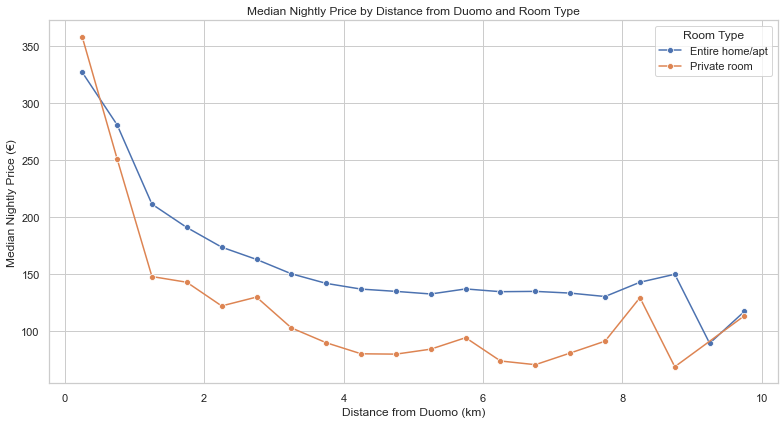

In [20]:
plt.figure(figsize=(11, 6))

sns.lineplot(
    data=distance_room_prices,
    x="distance_km",
    y="median_price",
    hue="room_type",
    marker="o"
)

plt.title("Median Nightly Price by Distance from Duomo and Room Type")
plt.xlabel("Distance from Duomo (km)")
plt.ylabel("Median Nightly Price (€)")
plt.legend(title="Room Type")

plt.tight_layout()
plt.show()

### Distance and Room Type: Key Findings

The relationship between distance from the Duomo and median nightly price remains visible when Entire home/apt and Private room listings are analysed separately.

- Both accommodation types show a substantial decline in median nightly prices within the first 4–5 km from the city centre.
- Entire home/apt listings exhibit a relatively stable median price of approximately €130–140 between 4.5 and 7.5 km.
- Private room listings also show a less pronounced decline beyond approximately 4 km, although their median prices fluctuate more substantially.
- Entire home/apt listings are considerably more numerous across distance intervals, which may contribute to more stable median estimates.
- At greater distances, particularly beyond 8 km, the small number of private room listings limits the reliability of the observed patterns.

These findings suggest that the relationship between geographic distance and nightly price is non-linear for both accommodation types.

The apparent price plateau is more clearly visible for entire homes, but additional statistical analysis would be required to determine whether differences in curve stability are primarily driven by sample size.

Overall, distance from the Duomo appears to be a potentially useful geographic predictor, even when room type is considered separately.

## 7. Key Findings and Implications for Model 2

### 7.1 Geographic Data Quality

The exploratory analysis was conducted on 21,314 listings, using the same selection criteria as Model 1.

- No missing values were found in latitude, longitude, or neighbourhood_cleansed.
- The dataset covers 87 distinct neighbourhoods.
- A total of 3,777 listings (17.7%) share their exact coordinates with at least one other listing, across 1,382 shared coordinate pairs.
- Coordinate ranges appear geographically plausible, and no listings were removed based on geographic information.

### 7.2 Spatial Distribution

Listings are unevenly distributed across Milan, with higher concentrations in central areas and a more dispersed pattern towards the outskirts.

Static and interactive maps reveal geographic clusters, although spatial proximity should not be confused with exact coordinate duplication.

### 7.3 Geographic Differences in Nightly Prices

Substantial differences in median nightly prices were observed across neighbourhoods.

Among the 15 most represented neighbourhoods, DUOMO (€293.25) and BRERA (€247.00) showed the highest median prices, while LODI - CORVETTO (€128.07) and LORETO (€134.00) showed the lowest.

These differences remained visible when Entire home/apt and Private room listings were analysed separately, suggesting that accommodation type alone does not explain the observed geographic variation.

The ratio between private room and entire home median prices varied considerably across neighbourhoods. Its correlation with the share of private room listings was weak (Pearson r = -0.103), providing no clear evidence of a linear association in the selected neighbourhoods.

### 7.4 Distance from Milan City Centre

Distances from the Duomo were calculated using both the Haversine formula and a locally approximated Euclidean metric. The resulting descriptive statistics were nearly identical within the geographic extent of the dataset.

Median nightly prices declined substantially within the first 4–5 km from the Duomo, followed by a less pronounced decrease and a possible plateau at greater distances.

This non-linear pattern remained visible when accommodation types were analysed separately.

The apparent plateau was more clearly defined for entire homes, while private room prices showed greater fluctuations, particularly in peripheral distance intervals with fewer listings.

### 7.5 Implications for Model 2

The exploratory findings support evaluating the following geographic predictors:

- Latitude and longitude, representing continuous geographic position.
- Neighbourhood information, representing categorical location characteristics.
- Distance from the Duomo, representing proximity to the city centre.

The observed non-linear distance-price relationship suggests that flexible modelling approaches may be useful.

Potential interactions between geographic position and accommodation type may also be investigated in subsequent modelling experiments.

However, exploratory associations do not guarantee improved predictive performance. The contribution of geographic variables must be evaluated using the same train/test split and comparable validation procedures as Model 1.

### 7.6 Next Steps

The next notebook will focus on geographic data preparation, including the selection, transformation, and encoding of geographic features.

The resulting features will then be evaluated in Model 2 using consistent cross-validation and test-set metrics, enabling a meaningful comparison with Model 1.